### Neurophysiology and Biophysics - Practical course WS 2024/25
__Cornelia Kopp-Scheinpflug & Kay Thurley__

# Miniproject: Encoding Sound Termination

In this notebook we simulate a neuron from the superior paraolivary nucleus (SPN) in the brainstem. It contains several conductances, i.a. iH channels, and receives inhibitory input from the medial nucleus of the trapezoid body (MNTB).
We use the model by Kopp-Scheinpflug et al. 2011 published on ModelDB. Converted to Python by Kay Thurley (2024).


_Requirements:_ You will need Neuron 8, Python 3 and the package Matplotlib for plotting.


We start by importing the relevant packages.

In [22]:
import numpy as np
from neurom.features.morphology import soma_radius
# import Neuron's hoc interpreter
from neuron import h
h.load_file('stdrun.hoc')

# set default units
from neuron.units import ms, mV

# import matplotlib for plotting
import matplotlib.pyplot as plt
import matplotlib
from scipy.signal import find_peaks
from collections import defaultdict
plt.style.use("bmh")

Then we define the model neuron and some parameters.

In [23]:
# -- default synapse parameters
syninterval = 10                # stimulus interval (ms)
synnum = 20                     # number of stimuli
syninterval2 = 10
synnum2 = 10
synnoise = 0                    # could be used to introduce some spike jitter
synconductance = 4e-3           # uS
nsyns = 14                      # how many inhibitory synapses does our neuron have?

gap = 75                        # default gap between the two stimulus trains
# -- load SPN neuron
h.load_file('spn_neuron.hoc')
soma = h.soma(0.5)
# stim = h.IClamp(soma)
# stim.delay = 200
# stim.amp = -400

Add stimuli and inputs.

In [24]:
# -- synapses
# set up inhibitory synapses
synstim = []
netsynstim = []
syn = []
for i in range(0, nsyns):
    synstim.append(h.NetStim(0.5))
    synstim[-1].start = 200
    synstim[-1].interval = syninterval
    synstim[-1].number = synnum
    synstim[-1].noise = synnoise
    syn.append(h.Exp2Syn(soma))
    syn[-1].e = -100
    syn[-1].tau1 = 0.1
    syn[-1].tau2 = 2
    netsynstim.append(h.NetCon(synstim[-1], syn[-1]))

# second stimulus (after the gap)
synstim2 = []
netsynstim2 = []
for i in range(0, nsyns):
    synstim2.append(h.NetStim(0.5))
    synstim2[-1].start = 300+gap
    synstim2[-1].interval = syninterval2
    synstim2[-1].number = synnum2
    synstim2[-1].noise = synnoise
    netsynstim2.append(h.NetCon(synstim2[-1], syn[-1]))
 
# -- noise source (simulates excitatory synaptic noise)
fl = h.mhh_Gfluct(0.5)	    # insert conductance based noise
fl.g_e0 = 0.000001		    # amplitude
fl.std_e = 0.0002	        # s-d
fl.tau_e = 2*0              # time constant
fl.E_e = 0                  # reversal potential


# noise
fl.std_e = 0.0005
fl.tau_e = 2

Settings for recording simulation results.

In [25]:
# vectors to store data
t_vec = h.Vector()                  # Time stamp vector
t_vec.record(h._ref_t)
v_vec = h.Vector()                  # membrane potential vector
v_vec.record(soma._ref_v)

syn_vecs = []
for i in range(nsyns):
    syn_vecs.append(h.Vector())
    syn_vecs[-1].record(syn[i]._ref_i)

ih_vec = h.Vector()                  # vector for stimulus current
ih_vec.record(soma.sjg_ih._ref_i)

Vector[52]

In [26]:
for seg in soma:
    print(seg)

print(soma.lva.gbar)

ca_ion
lva
sjg_ih
k_ion
LT
HT
na_ion
sjg_na
pas
0.0


Run a simulation.

In [27]:
# -- set synapse parameters
for i, synsti in enumerate(synstim):
    synsti.start = 300-syninterval*synnum
    synsti.interval = syninterval
    synsti.number = synnum
    synsti.noise = synnoise
    
    synstim2[i].start = 300+gap
    synstim2[i].interval = syninterval
    
    netsynstim[i].weight[0] = synconductance
    netsynstim2[i].weight[0] = synconductance


# -- run a simulation
h.tstop = 750           # duration of the simulation
nspikes = 0             # reset spike counter
h.finitialize(-60)
h.run()

0.0

In [28]:
gaps = np.arange(0, 90, 5)
gap_traces = {}
ap_count_apc = {}
ap_count = {}
apc = h.APCount(soma)
apc.thresh = 0
ap_times = h.Vector()
apc.record(ap_times)
t_start = 200
t_end = 400
Ih, Itca = 0.015, 0.0025
conds = {"full model" : {"Ih" : Ih, "Itca" : Itca}, "0.5 * Ih" : {"Ih" : Ih/2, "Itca" : Itca}, "No Itca" : {"Ih" : Ih, "Itca" : 0}}
output = {}
output_traces = {} 
for c, v in conds.items():
    soma.sjg_ih.ghbar = v["Ih"]
    soma.lva.gbar = v["Itca"]
    print(soma.sjg_ih.ghbar)
    print(soma.lva.gbar)
    gap_traces = {}
    ap_count_apc = {}
    for g in gaps:
        for i, synsti in enumerate(synstim):
            synsti.start = 300 - syninterval * synnum
            synsti.interval = syninterval
            synsti.number = synnum
            synsti.noise = synnoise

            synstim2[i].start = 300 + g
            synstim2[i].interval = syninterval2
            synstim2[i].number = synnum2
            synstim2[i].noise = synnoise

            netsynstim[i].weight[0] = synconductance
            netsynstim2[i].weight[0] = synconductance
        h.tstop = 750
        fl.new_seed(1)
        h.finitialize(-60)
        h.run()
        gap_traces[g] = v_vec.as_numpy().copy()
        selected_aps = [t for t in ap_times if t_start <= t <= t_end]
        ap_count_apc[g] = len(selected_aps)
    output[c] = ap_count_apc
    output_traces[c] = gap_traces


0.015
0.0025
0.0075
0.0025
0.015
0.0


KeyError: '0.5 * Ih'

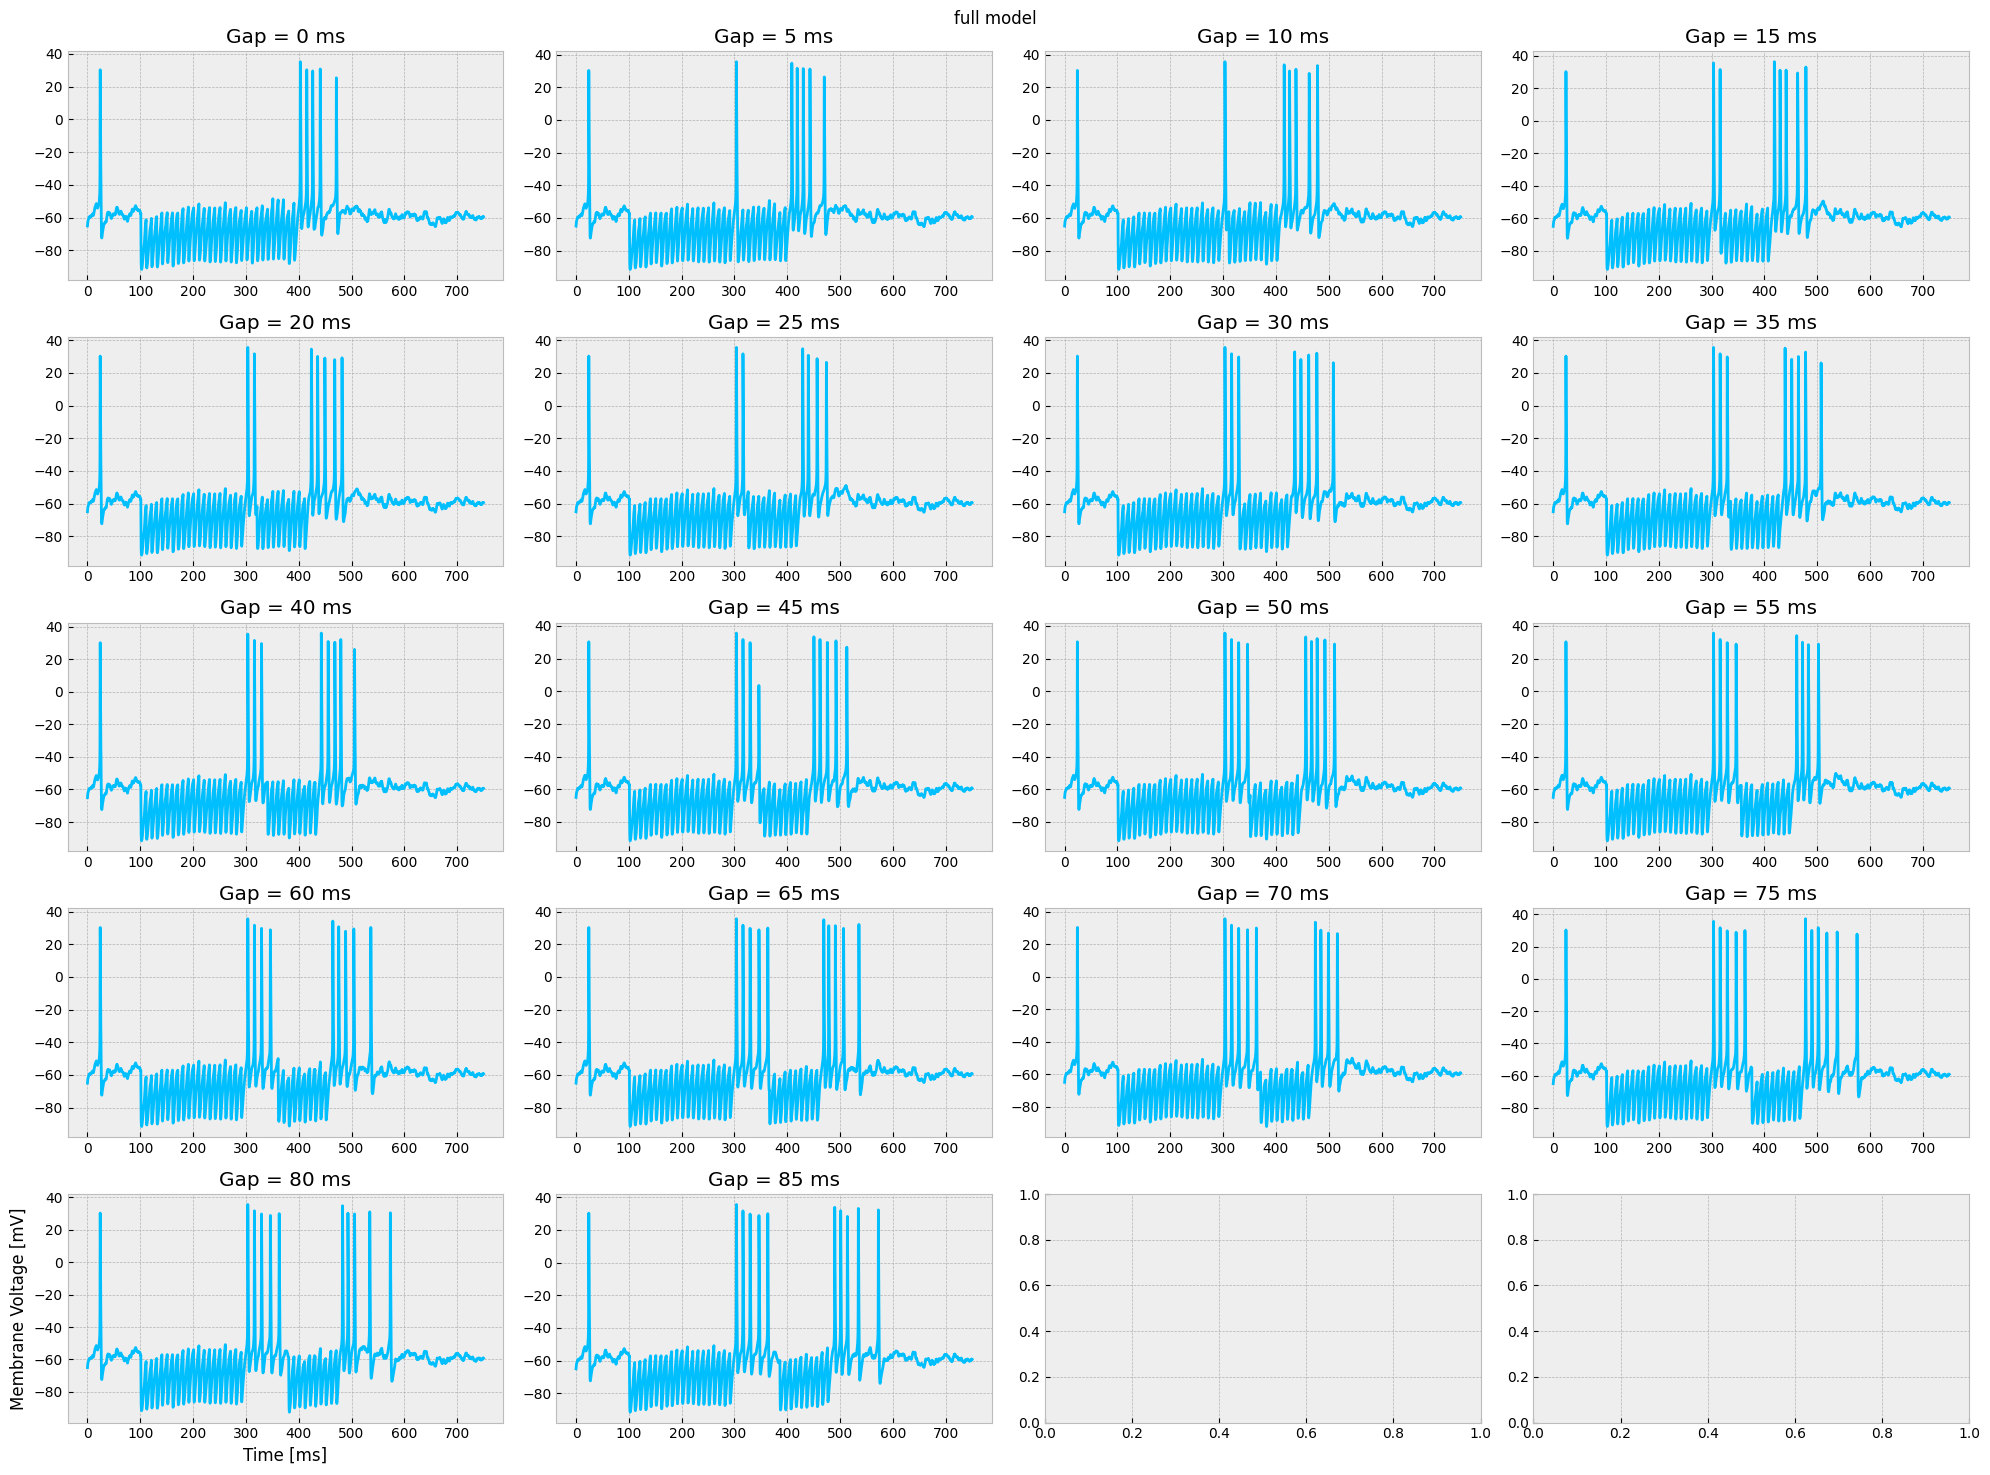

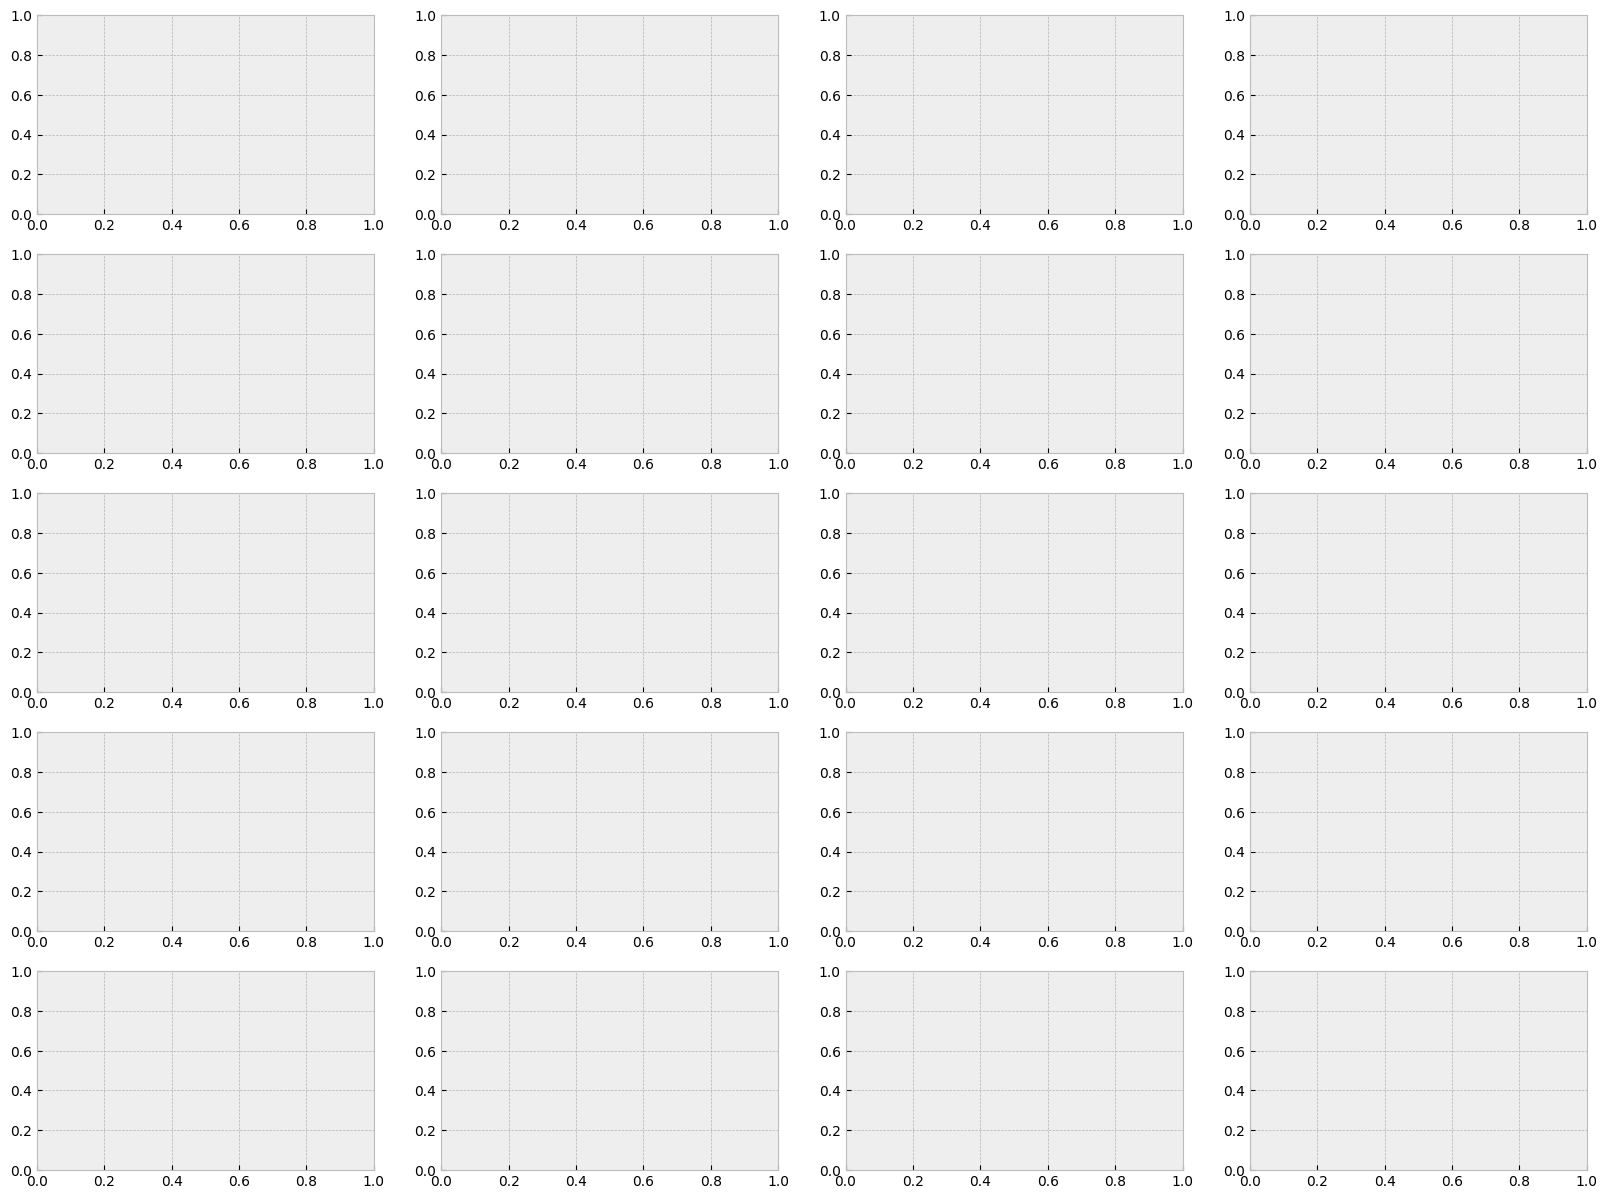

In [29]:
def display_gap_traces(gap_traces: dict, title: str):
    style = {"full model" : "deepskyblue", "05 * Ih" : "green", "No Itca" : "orange"}
    fig, ax = plt.subplots(5, 4, figsize=(20, 15))
    axes = ax.flat
    for i, (k, v) in enumerate(gap_traces.items()):
        axis = axes[i]
        axis.plot(t_vec, v, color=style[title])
        axis.set_title(f"Gap = {k} ms")
    ax[4, 0].set_ylabel("Membrane Voltage [mV]")
    ax[4, 0].set_xlabel("Time [ms]")
    fig.suptitle(title)
    fig.tight_layout()
for k, v in output_traces.items():
    display_gap_traces(gap_traces=v, title=k)


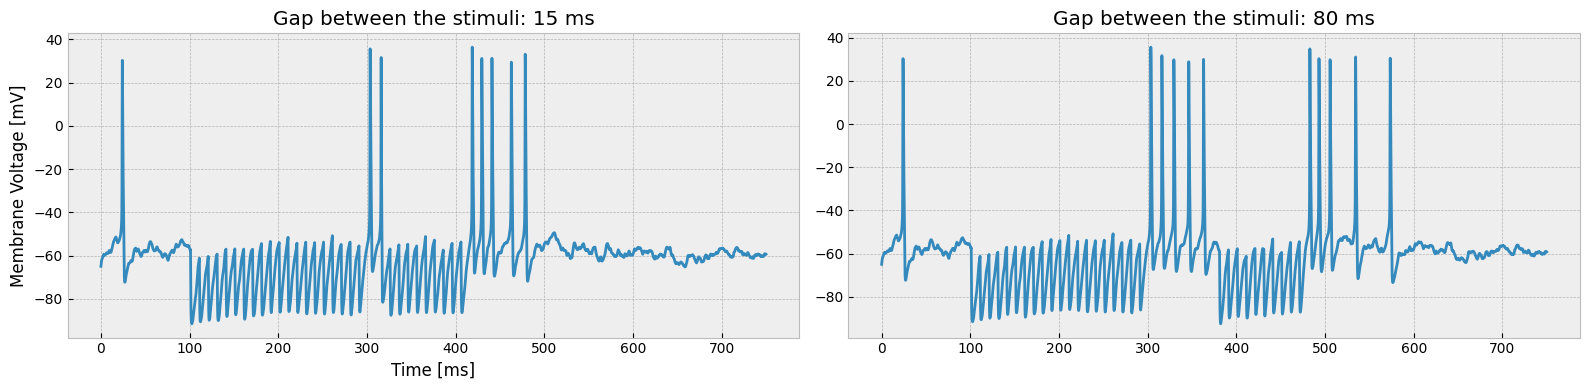

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ax[0].plot(t_vec, output_traces["full model"][15])
ax[0].set_title("Gap between the stimuli: 15 ms")
ax[1].plot(t_vec, output_traces["full model"][80])
ax[1].set_title("Gap between the stimuli: 80 ms")
ax[0].set_xlabel("Time [ms]")
ax[0].set_ylabel("Membrane Voltage [mV]")
fig.tight_layout()

Text(0, 0.5, 'AP number')

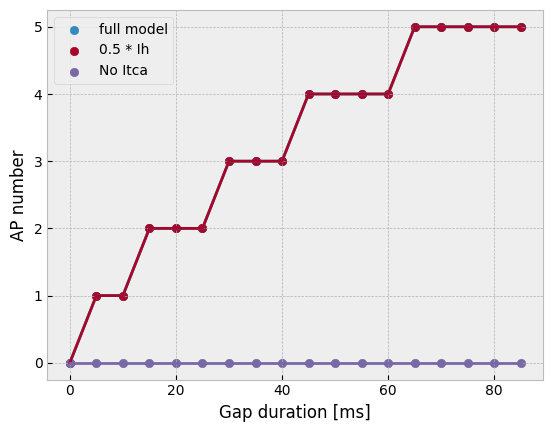

In [ ]:
fig, ax = plt.subplots(1,1)
for k, v in output.items():
    ax.scatter(list(v.keys()), list(v.values()), label=k)
    ax.plot(list(v.keys()), list(v.values()))
ax.legend()
ax.set_xlabel("Gap duration [ms]")
ax.set_ylabel("AP number")

In [ ]:
print(len(output_traces["full model"][30]))

30001


Plot the results.

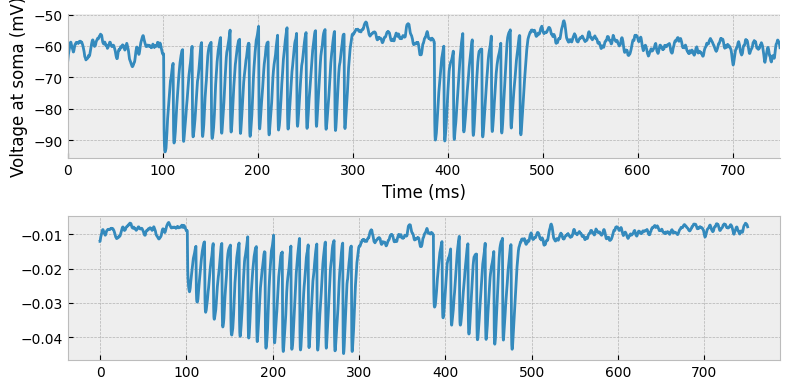

In [ ]:
h.tstop = 750           # duration of the simulation
nspikes = 0             # reset spike counter
h.finitialize(-60)
h.run()
fig, ax = plt.subplots(2, 1, figsize=(8, 4))
ax[0].set_ylabel('Voltage at soma ('+h.units('v')+')')
ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)
ax[0].set_xlabel('Time ('+h.units('t')+')')
ax[0].set_xlim([0, h.tstop])

ax[0].plot(t_vec, v_vec, '-')
ax[1].plot(t_vec, ih_vec)
fig.tight_layout()


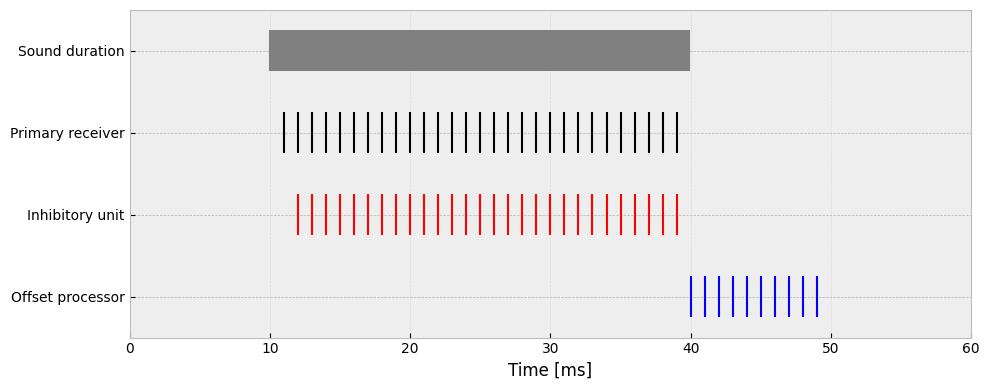

In [ ]:
sound = np.arange(10, 40, 0.1)
primary = np.arange(11, 40)
inhibitory = np.arange(12, 40)
offset = np.arange(40, 50)

fig, ax = plt.subplots(figsize=(10, 4))

ax.eventplot(
    [offset, inhibitory, primary, sound],
    orientation="horizontal",
    lineoffsets=[1, 2, 3, 4],
    linelengths=0.5,
    linewidths=1.5,
    colors=["blue", "red", "black", "gray"])

ax.set_xlabel("Time [ms]")

ax.set_yticks([1, 2, 3, 4])
ax.set_yticklabels([
    "Offset processor",
    "Inhibitory unit",
    "Primary receiver",
    "Sound duration"])

ax.set_xlim(0, 60)
ax.set_ylim(0.5, 4.5)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
